# 02 · Behavioural PD scorecard: champion, challengers, cutoff and fairness

**Summary.** The published PD champion reproduces exactly (test AUC 0.776, 95% CI 0.764-0.788; Gini 0.552; KS 0.421),
and so do the report's cutoff numbers (below 525: 30.5% of accounts, 63.0% of defaults, 54.4% of expected loss). A
six-characteristic WoE scorecard, with every coefficient signed the right way, reaches AUC 0.746: 0.030 below the champion
(paired 95% CI 0.023-0.037). A monotone-constrained LightGBM challenger matches the champion (+0.002, CI 0.000 to +0.004).
The champion stays; the monotone model is the candidate for the next release because it adds the guarantee validators ask
for at no measurable cost. PD is calibrated (mean 22.0% predicted vs 22.1% observed). At the cutoff every sex and age group
keeps its line at 81% or more of the best group's rate. Under-25s sit closest to the four-fifths flag (AIR 0.81), and PD
under-states risk for the over-55s. The binding limitation is the data: one 2005 snapshot, so stability over time cannot
be tested.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

import time
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
T0 = time.perf_counter()

## 1. Data, features and the split

The features are the ETL's 22 behavioural inputs (`features.pd_features`, unit-tested in `tests/test_features.py`):
credit limit, six monthly repayment-status codes, six monthly utilisations, five payment ratios, worst status, months
late, utilisation trend and average payment ratio. No sex, age, marital status or education.

**Split.** The ETL holds out 30% of cardholders, stratified on default. This data is a single snapshot: every account is
scored at the same date (September 2005) and observed for the same month, so there is no later cohort to hold out.
A random split is therefore the only option here, and it answers "does the score rank a new set of accounts from the
same period?". It cannot answer "does it still rank them a year later?", which is the question a production
scorecard has to answer. Section 9 shows what can be checked about stability, and the limitations say what cannot.

In [2]:
u = F.load_uci(ROOT)
X, y = F.pd_features(u), u["Default"].to_numpy()
itr, ite = F.pd_split(X, y)
Xtr, Xte, ytr, yte = X.iloc[itr], X.iloc[ite], y[itr], y[ite]
pub = pd.read_csv(ROOT / "data" / "model_metrics.csv").set_index("Metric")["Value"]
print(f"train {len(itr):,} accounts ({ytr.mean():.1%} default) | test {len(ite):,} accounts ({yte.mean():.1%} default) | {X.shape[1]} features")

train 21,000 accounts (22.1% default) | test 9,000 accounts (22.1% default) | 22 features


## 2. Reproduce the published champion first

The Power BI report, README and site quote the ETL's numbers. Before extending anything, refit the ETL's
HistGradientBoosting model and logistic regression with the same parameters on the same split and check the numbers.

In [3]:
champ = HistGradientBoostingClassifier(**F.ETL_PD_GBM).fit(Xtr, ytr)
p_champ = champ.predict_proba(Xte)[:, 1]
etl_logit = LogisticRegression(**F.ETL_PD_LOGIT).fit(Xtr, ytr)
p_etl_logit = etl_logit.predict_proba(Xte)[:, 1]
m_champ = evaluate.binary_metrics(yte, p_champ)
from sklearn.metrics import roc_auc_score
parity = pd.DataFrame({
    "published": [pub["pd_auc_test"], pub["pd_auc_train"], pub["pd_auc_logit"], pub["pd_ks_test"], pub["pd_gini_test"], pub["pd_default_rate"]],
    "reproduced": [m_champ["auc"], roc_auc_score(ytr, champ.predict_proba(Xtr)[:, 1]), roc_auc_score(yte, p_etl_logit), m_champ["ks"],
                   m_champ["gini"], y.mean()]},
    index=["Champion AUC, test", "Champion AUC, train", "Logistic AUC, test", "KS, test", "Gini, test", "Default rate"])
parity["difference"] = parity["reproduced"] - parity["published"]
assert (parity["difference"].abs() < 0.005).all(), parity
print(f"Champion stopped early after {champ.n_iter_} of {F.ETL_PD_GBM['max_iter']} iterations (sklearn's automatic early stopping on a 10% validation slice).")
parity

Champion stopped early after 72 of 300 iterations (sklearn's automatic early stopping on a 10% validation slice).


,published,reproduced,difference
"Champion AUC, test",0.7762,0.7762,0.0000
"Champion AUC, train",0.8095,0.8095,0.0000
"Logistic AUC, test",0.7404,0.7402,-0.0002
"KS, test",0.4214,0.4214,-0.0000
"Gini, test",0.5524,0.5524,0.0000
Default rate,0.2212,0.2212,0.0000


All six published numbers reproduce within 0.005 (the champion's test AUC exactly). The logistic differs in the
fourth decimal because its solver stops at a slightly different point on unscaled inputs. Everything below builds on
this model.

## 3. The candidates

| Candidate | Why it is in the comparison |
|---|---|
| **Rule: September status only** | Naive baseline: the default rate of the account's latest repayment bucket. Any model must beat this. |
| **WoE scorecard** | The format credit committees and model validators expect: monotonic WoE bins, IV and correlation filters, a logistic regression whose coefficients must all have the expected sign, then points. Fitted inside each fold. |
| **Logistic (ETL)** | The ETL's own baseline: raw inputs, no scaling. |
| **Logistic (standardised)** | The same model with standardised inputs, to check whether the ETL's baseline was handicapped. |
| **HistGradientBoosting (champion)** | The published model, ETL parameters. |
| **LightGBM, monotone (challenger)** | Gradient boosting with monotone constraints on every input whose direction is not in doubt (later or more frequent delinquency can only raise PD; a higher limit or payment ratio can only lower it). Utilisation is left free because of the U-shape in notebook 01. Tuned with Optuna. |
| **LightGBM, unconstrained** | The same tuned parameters without constraints: measures what monotonicity costs. |

### The scorecard

In [4]:
scorecard = make_pipeline(FunctionTransformer(F.scorecard_frame),
                          F.MonotonicWoEBinner(categorical=("status_1",), max_corr=0.7, max_features=8),
                          F.SignConstrainedLogit())
scorecard.fit(Xtr, ytr)
binner, sc_logit = scorecard[1], scorecard[2]
sc_summary = pd.DataFrame({"IV": pd.Series(binner.iv_)}).sort_values("IV", ascending=False)
sc_summary["kept by IV / correlation filter"] = sc_summary.index.isin(binner.selected_)
sc_summary["coefficient"] = pd.Series(dict(zip(binner.selected_, sc_logit.coef_[0])))
sc_summary["in final scorecard"] = sc_summary["coefficient"].fillna(0) != 0
sc_summary["label"] = [F.LABELS[f] for f in sc_summary.index]
sc_summary

,IV,kept by IV / correlation filter,coefficient,in final scorecard,label
status_1,0.8937,True,-0.6412,True,"Repayment status, Sep"
months_late,0.8880,False,NaN,False,"Months late, 6 months"
max_status,0.7793,True,-0.4215,True,"Worst repayment status, 6 months"
limit,0.1936,True,-0.4777,True,Credit limit
avg_payratio,0.1871,True,-0.4064,True,Average payment ratio
payratio_1,0.1598,True,-0.0457,True,"Payment ratio, Sep"
util_trend,0.0786,True,-0.3089,True,Utilisation trend (Sep minus Apr)
util_1,0.0600,True,0.0000,False,"Utilisation, Sep"


In [5]:
points = F.scorecard_points(binner, sc_logit)
points["label"] = points["feature"].map(F.LABELS)
factor, offset = F.factor_offset()
print(f"Scaling: score = {offset:.1f} + {factor:.2f} x ln(good:bad odds), i.e. 600 points at 50:1 and 20 points to double the odds.")
print(f"Characteristics in the final scorecard: {points['feature'].nunique()}; attributes (bins): {len(points)}")
show = points[points["feature"].isin(["status_1", "limit", "avg_payratio"])].copy()
show["points"] = show["points"].round(0).astype(int)
show[["label", "bin", "accounts_share", "bad_rate", "woe", "points"]].set_index(["label", "bin"])

Scaling: score = 487.1 + 28.85 x ln(good:bad odds), i.e. 600 points at 50:1 and 20 points to double the odds.
Characteristics in the final scorecard: 6; attributes (bins): 29


accounts_share  bad_rate     woe  points
label                 bin                                                           
Repayment status, Sep No use                        0.0920    0.1262  0.6743     100
                      Revolving                     0.4898    0.1264  0.6742     100
                      Paid in full                  0.1891    0.1697  0.3283      93
                      1 month late                  0.1246    0.3421 -0.6051      76
                      2 months late                 0.1045    0.6979 -2.0958      48
Credit limit          < 50,000                      0.1442    0.3689 -0.7219      77
                      50,000 to < 80,000            0.1635    0.2694 -0.2612      84
                      80,000 to < 140,000           0.1758    0.2373 -0.0917      86
                      140,000 to < 160,000          0.0618    0.1974  0.1426      89
                      160,000 to < 270,000          0.2499    0.1732  0.3037      91
                      >= 270,000                    0.2049    0.1306  0.6362      96
Average payment ratio < 0.0342                      0.1000    0.3833 -0.7835      78
                      0.0342 to < 0.0975            0.4000    0.2575 -0.1998      85
                      0.0975 to < 0.145             0.0500    0.2200  0.0054      87
                      0.145 to < 0.201              0.0500    0.1886  0.1987      90
                      0.201 to < 0.803              0.2500    0.1667  0.3503      91
                      >= 0.803                      0.1500    0.1184  0.7477      96

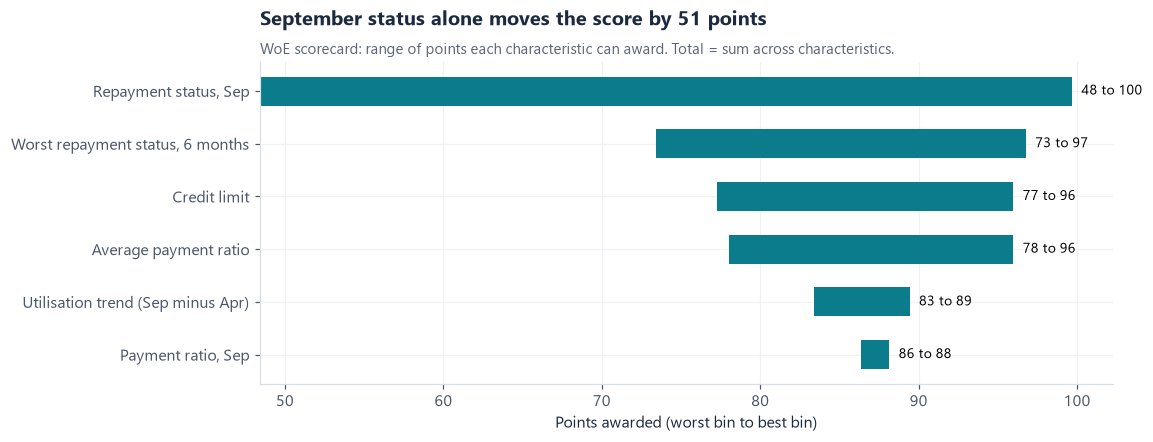

In [6]:
rng_pts = points.groupby("feature")["points"].agg(["min", "max"])
rng_pts["spread"] = rng_pts["max"] - rng_pts["min"]
rng_pts = rng_pts.sort_values("spread", ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.8))
lab = [F.LABELS[f] for f in rng_pts.index][::-1]
ax.barh(lab, rng_pts["spread"][::-1], left=rng_pts["min"][::-1], color=PALETTE["teal"], height=0.55)
for i, (lo_, hi_) in enumerate(zip(rng_pts["min"][::-1], rng_pts["max"][::-1])):
    ax.text(hi_ + 0.6, i, f"{lo_:.0f} to {hi_:.0f}", va="center", fontsize=9)
ax.set_xlabel("Points awarded (worst bin to best bin)")
headline(ax, f"September status alone moves the score by {rng_pts['spread'].iloc[0]:.0f} points",
         "WoE scorecard: range of points each characteristic can award. Total = sum across characteristics.")
_ = savefig(fig, "02-scorecard-points", FIG); plt.show()

The IV and correlation filters keep 7 of the 8 candidates. Months late is dropped because its WoE correlates above
0.7 with September status, the stronger characteristic. The sign check then removes September utilisation, whose
coefficient turns positive once status and trend are in. Six characteristics remain and every coefficient is negative,
so every extra point means lower risk. September status has the widest range (48 to 100 points). "No use" and
"Revolving" earn the same points because their default rates are the same (12.6%). The unit tests check that the points
table adds up to the scaled log-odds, so a credit officer can score an account by hand.

### Tuning the monotone LightGBM challenger

Optuna (TPE), 3-fold stratified CV on the training set only, AUC objective, a fixed budget. The test set is not touched.

20 trials, best CV AUC 0.7886


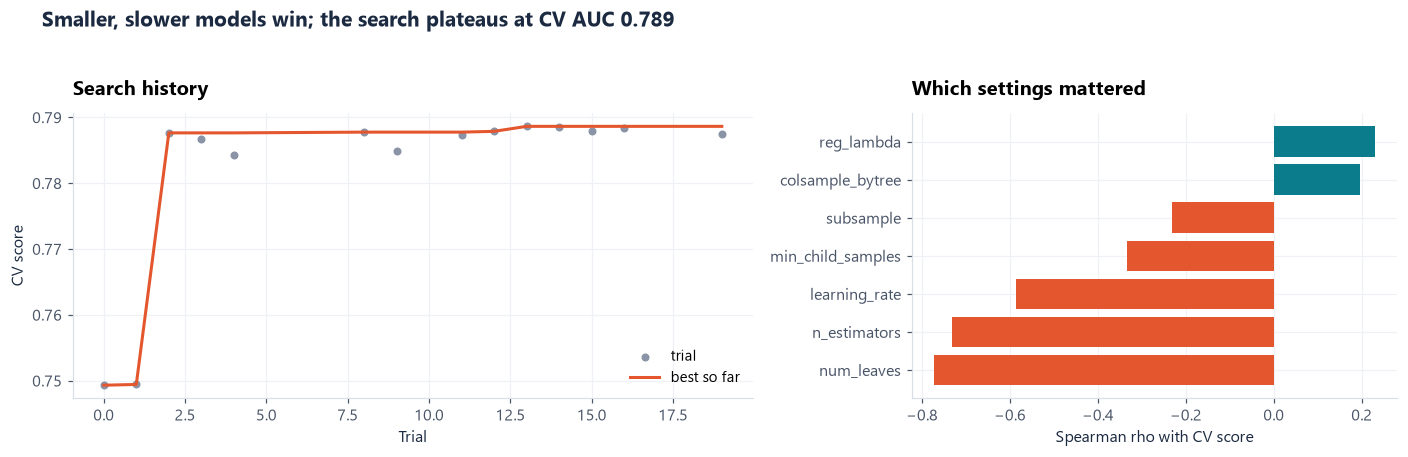

{'subsample_freq': 1,
 'random_state': 42,
 'verbose': -1,
 'n_jobs': 4,
 'n_estimators': 200,
 'learning_rate': 0.0287,
 'num_leaves': 11,
 'min_child_samples': 27,
 'subsample': 0.663,
 'colsample_bytree': 0.6451,
 'reg_lambda': 5.0357,
 'monotone_constraints_method': 'advanced'}

In [7]:
mono = [F.MONOTONE.get(c, 0) for c in X.columns]
fixed = {"monotone_constraints": mono, "monotone_constraints_method": "advanced"}
best, study = select.tune_lgbm(Xtr, ytr, StratifiedKFold(3, shuffle=True, random_state=SEED), n_trials=20, timeout=300, fixed=fixed, seed=SEED)  # trial-bound: same result on a busy machine
print(f"{len(study.trials)} trials, best CV AUC {study.best_value:.4f}")
fig = select.plot_optuna(study, title=f"Smaller, slower models win; the search plateaus at CV AUC {study.best_value:.3f}"); plt.show()
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items() if k != "monotone_constraints"}

## 4. Compare on identical folds

Five stratified folds of the training set, the same folds for every candidate. Mean and spread of AUC, average
precision and Brier score.

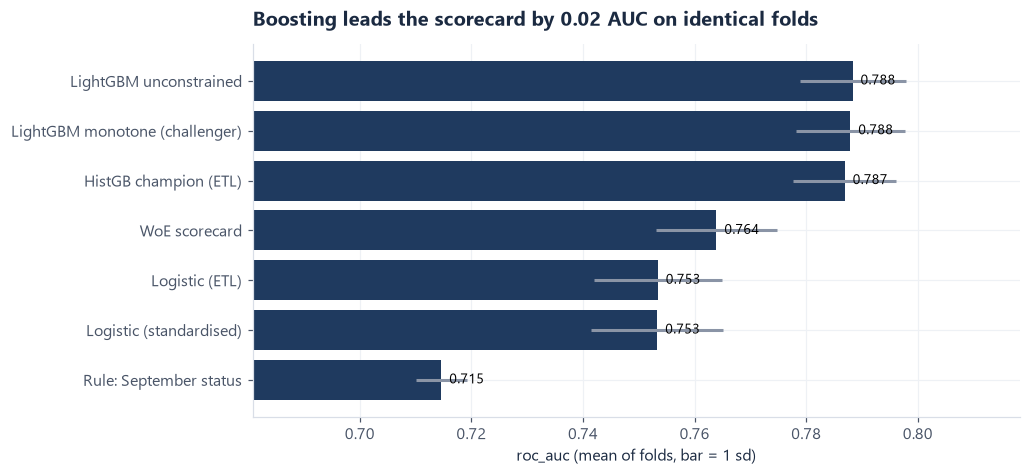

,fit_seconds,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_score_mean,brier_score_std
model,,,,,,,
Rule: September status,0.0300,0.7146,0.0046,0.4587,0.0090,0.1409,0.0018
WoE scorecard,0.2800,0.7639,0.0108,0.5347,0.0128,0.1362,0.0022
Logistic (ETL),1.2100,0.7534,0.0115,0.5096,0.0127,0.1405,0.0020
Logistic (standardised),0.0500,0.7533,0.0118,0.5099,0.0132,0.1405,0.0021
HistGB champion (ETL),0.2200,0.7869,0.0092,0.5621,0.0125,0.1333,0.0026
LightGBM monotone (challenger),0.4200,0.7879,0.0098,0.5631,0.0116,0.1329,0.0026
LightGBM unconstrained,0.2800,0.7883,0.0095,0.5639,0.0119,0.1328,0.0026


In [8]:
rule = make_pipeline(ColumnTransformer([("status", OneHotEncoder(handle_unknown="ignore"), ["status_1"])]), LogisticRegression(max_iter=1000))
models = {
    "Rule: September status": rule,
    "WoE scorecard": scorecard,
    "Logistic (ETL)": LogisticRegression(**F.ETL_PD_LOGIT),
    "Logistic (standardised)": make_pipeline(StandardScaler(), LogisticRegression(**F.ETL_PD_LOGIT)),
    "HistGB champion (ETL)": HistGradientBoostingClassifier(**F.ETL_PD_GBM),
    "LightGBM monotone (challenger)": lgb.LGBMClassifier(**best),
    "LightGBM unconstrained": lgb.LGBMClassifier(**{k: v for k, v in best.items() if not k.startswith("monotone")}),
}
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
cvt = select.cv_compare(models, Xtr, ytr, cv5)
fig, ax = plt.subplots(figsize=(9, 4.4))
select.plot_cv_compare(cvt, "roc_auc", ax=ax, title="Boosting leads the scorecard by 0.02 AUC on identical folds")
plt.show()
cvt

* The three boosting models sit within 0.002 AUC of each other (0.787-0.788) and 0.023 above the WoE scorecard (0.764).
* The scorecard beats both logistic regressions (0.753) with 6 inputs instead of 22: WoE bins capture the step in risk at
  two months late, which a linear term on the raw status code cannot.
* Standardising the ETL's logistic changes nothing (0.7533 vs 0.7534), so the published logistic baseline was fair.
* The September-status rule alone reaches 0.715: most of the signal is one field. Everything else adds about 0.07.

## 5. The untouched test set: discrimination with confidence intervals

In [9]:
fitted = {name: (m if name == "WoE scorecard" else m.fit(Xtr, ytr)) for name, m in models.items()}
fitted["HistGB champion (ETL)"] = champ
preds = {name: m.predict_proba(Xte)[:, 1] for name, m in fitted.items()}
mt = evaluate.metrics_table(yte, preds, n_boot=300, seed=SEED)
mt["Gini"] = 2 * mt["AUC"] - 1
mt[["AUC", "AUC 95% CI", "Gini", "KS", "PR AUC", "PR AUC 95% CI", "Brier", "Log loss"]]

,AUC,AUC 95% CI,Gini,KS,PR AUC,PR AUC 95% CI,Brier,Log loss
model,,,,,,,,
Rule: September status,0.7004,0.687 - 0.715,0.4008,0.3599,0.4448,0.428 - 0.464,0.1431,0.4567
WoE scorecard,0.7460,0.732 - 0.758,0.4920,0.3982,0.5116,0.492 - 0.534,0.1399,0.4464
Logistic (ETL),0.7402,0.726 - 0.753,0.4804,0.3909,0.4953,0.474 - 0.518,0.1433,0.4534
Logistic (standardised),0.7400,0.725 - 0.753,0.4800,0.3900,0.4957,0.476 - 0.518,0.1433,0.4535
HistGB champion (ETL),0.7762,0.764 - 0.788,0.5524,0.4214,0.5516,0.531 - 0.573,0.1357,0.4317
LightGBM monotone (challenger),0.7782,0.765 - 0.789,0.5564,0.4238,0.5518,0.531 - 0.574,0.1355,0.4311
LightGBM unconstrained,0.7797,0.767 - 0.791,0.5594,0.4297,0.5541,0.531 - 0.575,0.1352,0.4303


In [10]:
pairs = {
    "LightGBM monotone - champion": ("LightGBM monotone (challenger)", "HistGB champion (ETL)"),
    "LightGBM unconstrained - LightGBM monotone": ("LightGBM unconstrained", "LightGBM monotone (challenger)"),
    "Champion - WoE scorecard": ("HistGB champion (ETL)", "WoE scorecard"),
    "WoE scorecard - Logistic (standardised)": ("WoE scorecard", "Logistic (standardised)"),
    "Champion - Rule: September status": ("HistGB champion (ETL)", "Rule: September status"),
}
paired = pd.DataFrame({k: evaluate.paired_auc_test(yte, preds[a], preds[b], n=1000, seed=SEED) for k, (a, b) in pairs.items()}).T
paired

,delta_auc,ci_low,ci_high,p_value_one_sided
LightGBM monotone - champion,0.0020,0.0000,0.0039,0.0240
LightGBM unconstrained - LightGBM monotone,0.0016,0.0003,0.0028,0.0050
Champion - WoE scorecard,0.0302,0.0232,0.0372,0.0000
WoE scorecard - Logistic (standardised),0.0060,0.0008,0.0112,0.0090
Champion - Rule: September status,0.0758,0.0651,0.0869,0.0000


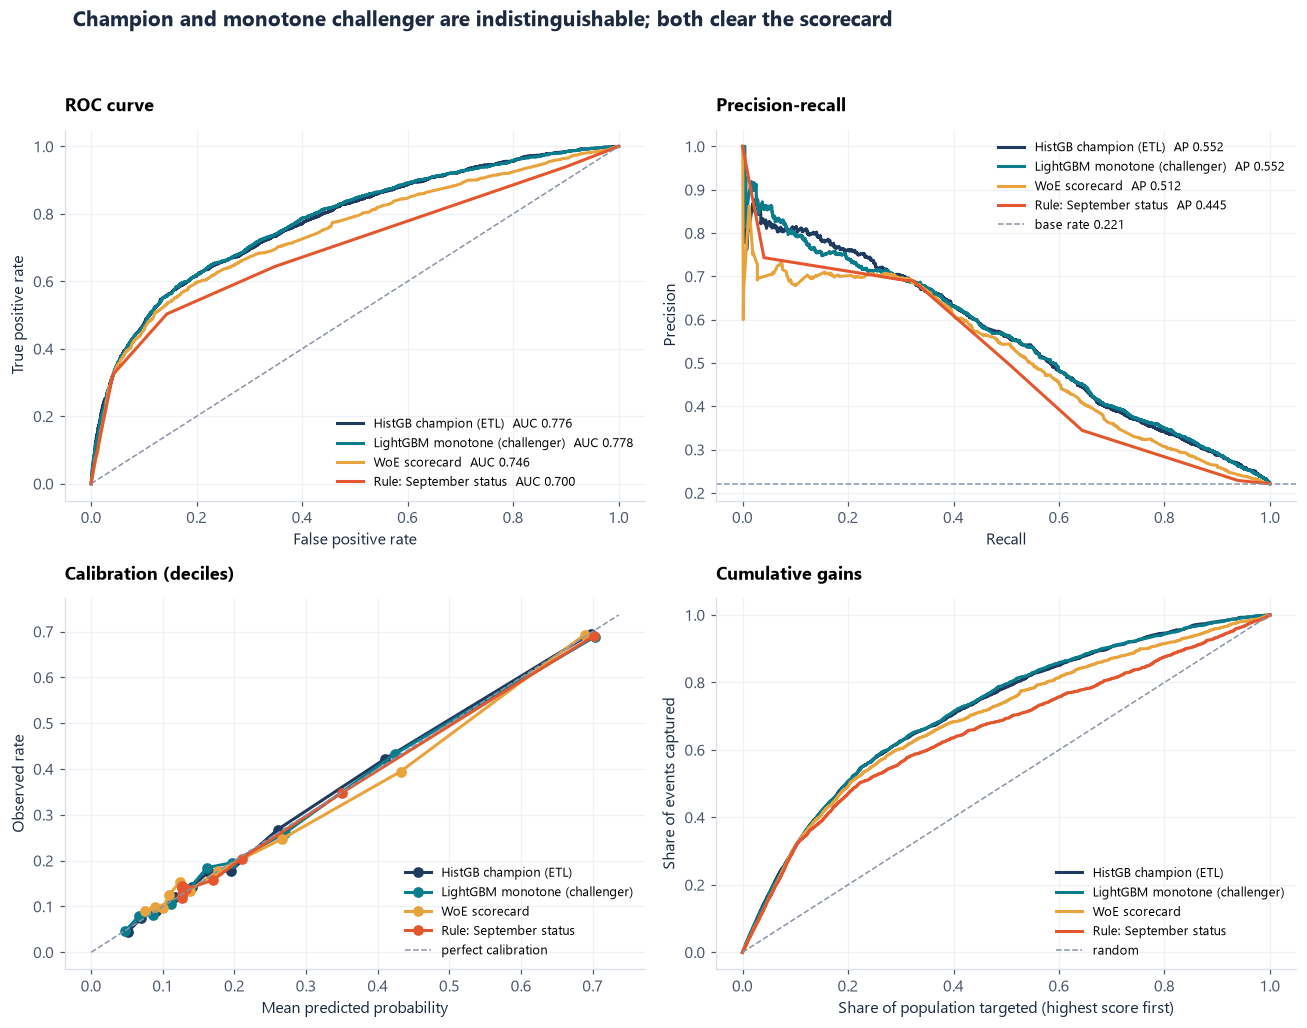

In [11]:
show_models = ["HistGB champion (ETL)", "LightGBM monotone (challenger)", "WoE scorecard", "Rule: September status"]
fig = evaluate.plot_binary_panel(yte, {k: preds[k] for k in show_models},
                                 suptitle="Champion and monotone challenger are indistinguishable; both clear the scorecard")
_ = savefig(fig, "02-model-panel", FIG); plt.show()

The hold-out confirms the CV ranking.

* **Champion vs monotone challenger:** 0.776 vs 0.778. The paired bootstrap difference is +0.002 (95% CI 0.000 to +0.004,
  one-sided p = 0.02). The interval touches zero and the gain is worth almost nothing at the cutoff (63.1% vs 63.0% of
  defaults caught at the 525 volume): the two models are equivalent in practice.
* **Cost of monotonicity:** dropping the constraints adds 0.0016 AUC on test (CI 0.0003 to 0.0028). CV showed 0.0004, so
  the cost is real but small.
* **Champion vs scorecard:** +0.030 AUC (CI 0.023 to 0.037). The scorecard beats the logistic by 0.006 (CI 0.001 to 0.011).
* **Champion vs the status rule:** +0.076 AUC. The model earns its complexity.

## 6. Calibration

The score is used to compute expected loss (PD x exposure x LGD), so the PD itself has to be right, not only the
ranking.

In [12]:
cal = pd.concat({k: evaluate.calibration_table(yte, preds[k], 10) for k in show_models[:3]}, axis=1)
cal_summary = pd.DataFrame({k: {"mean predicted PD": preds[k].mean(), "observed default rate": yte.mean(),
                                "calibration-in-the-large (pred / obs)": preds[k].mean() / yte.mean(),
                                "max decile gap (pp)": 100 * (evaluate.calibration_table(yte, preds[k], 10).eval("predicted - observed")).abs().max(),
                                "Brier": evaluate.binary_metrics(yte, preds[k])["brier"]} for k in show_models[:3]}).T
cal_summary

,mean predicted PD,observed default rate,calibration-in-the-large (pred / obs),max decile gap (pp),Brier
HistGB champion (ETL),0.2195,0.2212,0.9923,1.6827,0.1357
LightGBM monotone (challenger),0.2203,0.2212,0.9960,2.2862,0.1355
WoE scorecard,0.2198,0.2212,0.9938,3.7294,0.1399


In [13]:
from sklearn.calibration import CalibratedClassifierCV
iso = CalibratedClassifierCV(HistGradientBoostingClassifier(**F.ETL_PD_GBM), method="isotonic", cv=cv5).fit(Xtr, ytr)
p_iso = iso.predict_proba(Xte)[:, 1]
pd.DataFrame({"champion": evaluate.binary_metrics(yte, p_champ), "champion + isotonic (5-fold)": evaluate.binary_metrics(yte, p_iso)}).T[["auc", "brier", "log_loss", "mean_pred", "base_rate"]]

,auc,brier,log_loss,mean_pred,base_rate
champion,0.7762,0.1357,0.4317,0.2195,0.2212
champion + isotonic (5-fold),0.7777,0.1355,0.4312,0.2203,0.2212


All three models are calibrated in the large: mean PD within 1% of the observed 22.1%. The champion's worst decile is
off by 1.7 percentage points. Isotonic recalibration fitted inside five folds moves the Brier score by 0.0002, so no
recalibration is needed; a step that changes nothing is only one more thing to maintain. This is the easy case,
though: a random split from one month. On a later cohort with a different default rate, calibration is the first thing
that breaks, which is why the monitoring plan in the model card tracks predicted vs observed PD every month.

## 7. From score to decision: the 525 cutoff

Scores use the ETL scaling: 600 points at 50:1 good:bad odds, 20 points to double the odds, clipped to 300-850. The
policy the report simulates: accounts below 525 get a credit-line review. Expected loss = PD x exposure at default x
LGD; LGD is a single assumption (0.75 in the report), so it cancels out of every share below.

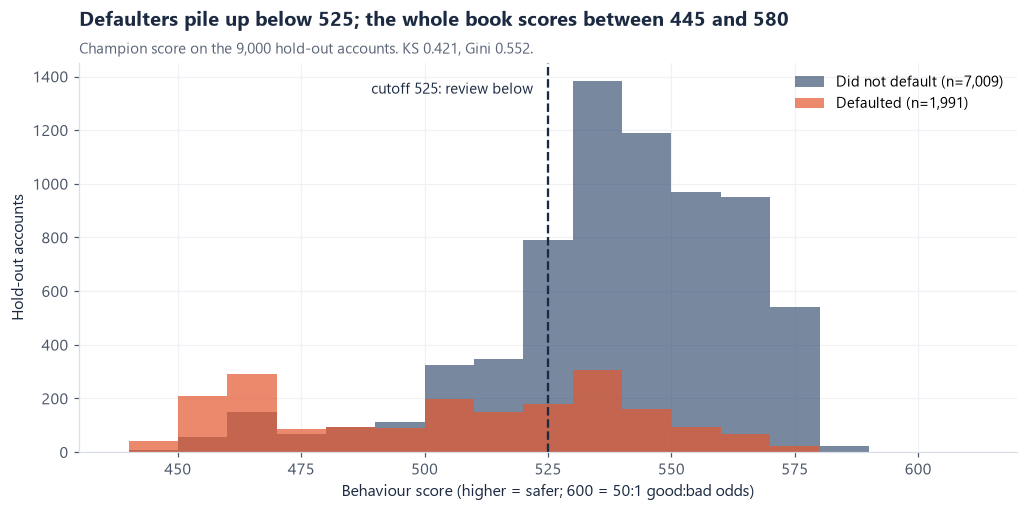

In [14]:
ead = F.exposure_at_default(u).to_numpy()[ite]
te = pd.DataFrame({"score": F.score_points(p_champ), "pd": p_champ, "default": yte, "ead": ead}, index=Xte.index)
te["el"] = te["pd"] * te["ead"]
te["band"] = F.score_band(te["score"]).values
fig, ax = plt.subplots(figsize=(11, 4.6))
bins = np.arange(300, 860, 10)
ax.hist(te.loc[te["default"] == 0, "score"], bins=bins, color=PALETTE["navy"], alpha=0.6, label=f"Did not default (n={int((te['default'] == 0).sum()):,})")
ax.hist(te.loc[te["default"] == 1, "score"], bins=bins, color=PALETTE["coral"], alpha=0.7, label=f"Defaulted (n={int(te['default'].sum()):,})")
ax.axvline(525, color=PALETTE["ink"], lw=1.5, ls="--")
ax.text(522, ax.get_ylim()[1] * 0.92, "cutoff 525: review below", ha="right", fontsize=9.5, color=PALETTE["ink"])
ax.set(xlabel="Behaviour score (higher = safer; 600 = 50:1 good:bad odds)", ylabel="Hold-out accounts", xlim=(430, 620))
ax.legend(loc="upper right")
headline(ax, f"Defaulters pile up below 525; the whole book scores between {te['score'].min()} and {te['score'].max()}",
         f"Champion score on the 9,000 hold-out accounts. KS {m_champ['ks']:.3f}, Gini {m_champ['gini']:.3f}.")
_ = savefig(fig, "02-score-distribution", FIG); plt.show()

In [15]:
TIER = {"Under 450": "1. Decrease line + collections call", "450-499": "1. Decrease line + collections call",
        "500-524": "2. Analyst review", "525-549": "3. Maintain", "550-574": "3. Maintain", "575-599": "4. Eligible for a limit increase",
        "600-624": "4. Eligible for a limit increase", "625-649": "4. Eligible for a limit increase", "650+": "4. Eligible for a limit increase"}
bt = te.groupby("band", observed=False).agg(accounts=("default", "size"), defaults=("default", "sum"), el=("el", "sum"), mean_pd=("pd", "mean"))
bt["share_of_accounts"] = bt["accounts"] / bt["accounts"].sum()
bt["bad_rate"] = bt["defaults"] / bt["accounts"]
bt["share_of_defaults"] = bt["defaults"] / bt["defaults"].sum()
bt["share_of_expected_loss"] = bt["el"] / bt["el"].sum()
for c in ("share_of_accounts", "share_of_defaults", "share_of_expected_loss"):
    bt[f"cum_{c}"] = bt[c].cumsum()
bt["policy"] = bt.index.map(TIER)
print(f"Scores on the hold-out run from {te['score'].min()} to {te['score'].max()}; bands with no accounts are left out.")
bt = bt[bt["accounts"] > 0]
bt[["policy", "accounts", "share_of_accounts", "bad_rate", "mean_pd", "share_of_defaults", "share_of_expected_loss",
    "cum_share_of_accounts", "cum_share_of_defaults", "cum_share_of_expected_loss"]]

Scores on the hold-out run from 445 to 580; bands with no accounts are left out.


,policy,accounts,share_of_accounts,bad_rate,mean_pd,share_of_defaults,share_of_expected_loss,cum_share_of_accounts,cum_share_of_defaults,cum_share_of_expected_loss
band,,,,,,,,,,
Under 450,1. Decrease line + collections call,49,0.0054,0.8571,0.7981,0.0211,0.0058,0.0054,0.0211,0.0058
450-499,1. Decrease line + collections call,1253,0.1392,0.6153,0.6246,0.3872,0.3462,0.1447,0.4083,0.3521
500-524,2. Analyst review,1445,0.1606,0.3059,0.2903,0.2220,0.1923,0.3052,0.6303,0.5444
525-549,3. Maintain,3587,0.3986,0.1542,0.1527,0.2777,0.3060,0.7038,0.9081,0.8503
550-574,3. Maintain,2425,0.2694,0.0726,0.0728,0.0884,0.1388,0.9732,0.9965,0.9891
575-599,4. Eligible for a limit increase,241,0.0268,0.0290,0.0425,0.0035,0.0109,1.0000,1.0000,1.0000


In [16]:
pol = bt.groupby("policy").agg(accounts=("accounts", "sum"), defaults=("defaults", "sum"), el=("el", "sum"))
pol["share_of_accounts"] = pol["accounts"] / pol["accounts"].sum()
pol["bad_rate"] = pol["defaults"] / pol["accounts"]
pol["share_of_defaults"] = pol["defaults"] / pol["defaults"].sum()
pol["share_of_expected_loss"] = pol["el"] / pol["el"].sum()
act = te["score"] < 525
cut = {"share_of_accounts": act.mean(), "share_of_defaults": te.loc[act, "default"].sum() / te["default"].sum(),
       "share_of_expected_loss": te.loc[act, "el"].sum() / te["el"].sum(), "bad_rate_actioned": te.loc[act, "default"].mean(),
       "bad_rate_kept": te.loc[~act, "default"].mean(), "good_accounts_actioned": int((act & (te["default"] == 0)).sum())}
assert abs(cut["share_of_accounts"] - 0.31) < 0.01 and abs(cut["share_of_defaults"] - 0.63) < 0.01 and abs(cut["share_of_expected_loss"] - 0.54) < 0.01
print("Cutoff 525 (published: 31% of accounts, 63% of defaults, 54% of expected loss):")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in cut.items()})
pol[["accounts", "share_of_accounts", "bad_rate", "share_of_defaults", "share_of_expected_loss"]]

Cutoff 525 (published: 31% of accounts, 63% of defaults, 54% of expected loss):
{'share_of_accounts': np.float64(0.3052), 'share_of_defaults': np.float64(0.6303), 'share_of_expected_loss': np.float64(0.5444), 'bad_rate_actioned': np.float64(0.4569), 'bad_rate_kept': np.float64(0.1177), 'good_accounts_actioned': 1492}


,accounts,share_of_accounts,bad_rate,share_of_defaults,share_of_expected_loss
policy,,,,,
1. Decrease line + collections call,1302,0.1447,0.6244,0.4083,0.3521
2. Analyst review,1445,0.1606,0.3059,0.2220,0.1923
3. Maintain,6012,0.6680,0.1213,0.3661,0.4447
4. Eligible for a limit increase,241,0.0268,0.0290,0.0035,0.0109


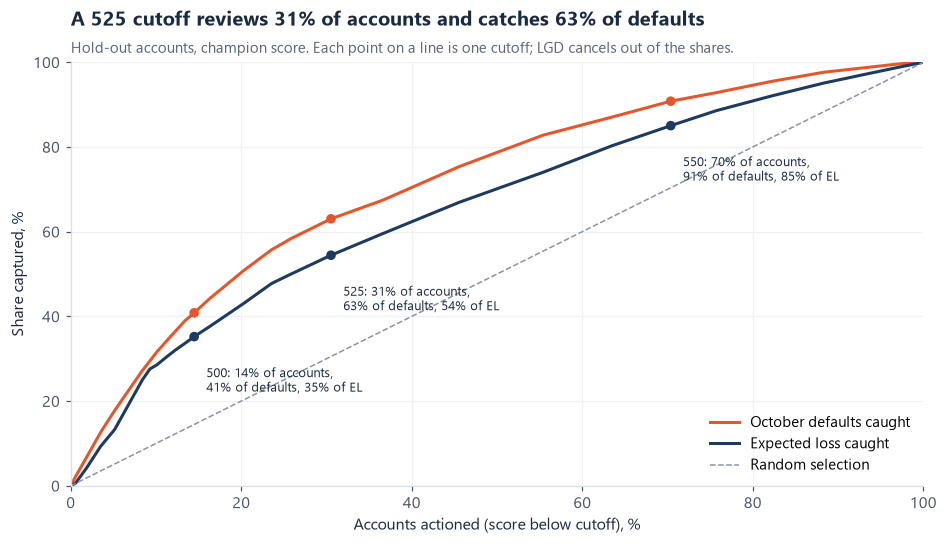

In [17]:
cuts = np.arange(400, 701, 5)
curve = pd.DataFrame([{"cutoff": c, "accounts": (te["score"] < c).mean(), "defaults": te.loc[te["score"] < c, "default"].sum() / te["default"].sum(),
                       "el": te.loc[te["score"] < c, "el"].sum() / te["el"].sum()} for c in cuts])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve["accounts"] * 100, curve["defaults"] * 100, color=PALETTE["coral"], label="October defaults caught")
ax.plot(curve["accounts"] * 100, curve["el"] * 100, color=PALETTE["navy"], label="Expected loss caught")
ax.plot([0, 100], [0, 100], ls="--", color=PALETTE["grey"], lw=1, label="Random selection")
for c in (500, 525, 550):
    r = curve.set_index("cutoff").loc[c]
    ax.scatter([r["accounts"] * 100] * 2, [r["defaults"] * 100, r["el"] * 100], color=[PALETTE["coral"], PALETTE["navy"]], zorder=3, s=28)
    ax.annotate(f"{c}: {r['accounts']:.0%} of accounts,\n{r['defaults']:.0%} of defaults, {r['el']:.0%} of EL", (r["accounts"] * 100, r["el"] * 100),
                xytext=(8, -36), textcoords="offset points", fontsize=8.5, color=PALETTE["ink"])
ax.set(xlabel="Accounts actioned (score below cutoff), %", ylabel="Share captured, %", xlim=(0, 100), ylim=(0, 100))
ax.legend(loc="lower right")
headline(ax, "A 525 cutoff reviews 31% of accounts and catches 63% of defaults",
         "Hold-out accounts, champion score. Each point on a line is one cutoff; LGD cancels out of the shares.")
_ = savefig(fig, "02-cutoff-strategy", FIG); plt.show()

The published numbers reproduce: below 525 sit 30.5% of hold-out accounts, holding 63.0% of October defaults and
54.4% of expected loss. The reviewed group defaults at 45.7%, against 11.8% for accounts that keep their line. The cost
is 1,492 reviewed accounts that would have paid. That is why the 500-524 band goes to an analyst rather than an
automatic cut.

Two things the table shows that the dashboard does not:

* **The score scale is compressed.** Every hold-out account scores between 445 and 580. 600 points means 50:1 odds (PD 2%), and
  in a book with a 22% default rate almost nobody is that safe. The limit-increase tier (575+) holds 2.7% of accounts, with
  a 2.9% bad rate.
* **Expected loss is less concentrated than defaults** (54% vs 63% below 525), because the riskiest accounts tend to have
  lower limits and smaller exposures. A loss-focused policy would rank on PD x exposure, not on score alone.

**Same workload, different models.** What each model catches if the lowest-scoring 30.5% of accounts are reviewed
(the 525 volume). Realised loss = exposure at default of the accounts that did default, so the comparison does not
depend on any model's own PD.

In [18]:
k = int(round(cut["share_of_accounts"] * len(te)))
real_loss = te["default"] * te["ead"]
same_vol = {}
for name in ["Rule: September status", "WoE scorecard", "Logistic (standardised)", "HistGB champion (ETL)", "LightGBM monotone (challenger)"]:
    idx = np.argsort(-preds[name], kind="stable")[:k]
    same_vol[name] = {"defaults caught": te["default"].to_numpy()[idx].sum() / te["default"].sum(),
                      "realised loss caught": real_loss.to_numpy()[idx].sum() / real_loss.sum(),
                      "bad rate of reviewed accounts": te["default"].to_numpy()[idx].mean()}
pd.DataFrame(same_vol).T

,defaults caught,realised loss caught,bad rate of reviewed accounts
Rule: September status,0.5620,0.5227,0.4074
WoE scorecard,0.6067,0.5119,0.4398
Logistic (standardised),0.6052,0.5139,0.4387
HistGB champion (ETL),0.6303,0.5435,0.4569
LightGBM monotone (challenger),0.6308,0.5471,0.4572


At the same workload the champion and challenger catch 63% of defaults, the scorecard 61% and the status rule 56%. On
realised loss the order changes: the rule (52.3%) beats the scorecard (51.2%), because the scorecard's credit-limit
points steer it towards low-limit, low-exposure accounts. The boosting models lead on both measures (54.4-54.7%).

## 8. Fairness at the cutoff

Sex and age are not inputs. The question here is whether the outcome of the policy differs by group, and whether any
difference is explained by risk. "Kept" means the account scores 525 or more and keeps its line. Adverse-impact ratio
(AIR) = a group's kept rate divided by the highest group's kept rate; below 0.80 is the usual flag (the four-fifths
rule). Each group's AUC and calibration ratio show whether the score is equally accurate for that group.

In [19]:
grp = pd.DataFrame({"Sex": u["SEX"].map({1: "Male", 2: "Female"}).to_numpy()[ite], "Age band": F.band(u["AGE"], F.AGE_BANDS).to_numpy()[ite],
                    "kept": ~act.to_numpy(), "default": yte, "pd": p_champ})
fair = []
for g in ("Sex", "Age band"):
    t = grp.groupby(g).agg(accounts=("default", "size"), default_rate=("default", "mean"), mean_pd=("pd", "mean"), kept_rate=("kept", "mean"))
    t["AIR"] = t["kept_rate"] / t["kept_rate"].max()
    t["bad_rate_kept"] = grp[grp["kept"]].groupby(g)["default"].mean()
    t["bad_rate_actioned"] = grp[~grp["kept"]].groupby(g)["default"].mean()
    seg = evaluate.segment_performance(grp.rename(columns={g: "group"}), "group", "default", "pd", min_n=100)
    t["auc"], t["calibration_ratio"] = seg["auc"], seg["calibration_ratio"]
    t.index = pd.MultiIndex.from_product([[g], t.index])
    fair.append(t)
fair = pd.concat(fair).reindex([("Sex", "Female"), ("Sex", "Male")] + [("Age band", b) for b in F.AGE_BANDS[1]])
fair

accounts  default_rate  mean_pd  kept_rate    AIR  bad_rate_kept  bad_rate_actioned    auc  calibration_ratio
Sex      Female        5437        0.2099   0.2157     0.7041 1.0000         0.1092             0.4493 0.7828             1.0276
         Male          3563        0.2386   0.2254     0.6806 0.9667         0.1311             0.4675 0.7662             0.9449
Age band Under 25       802        0.2668   0.2779     0.5810 0.8124         0.1245             0.4643 0.7749             1.0416
         25-34         3856        0.1971   0.2094     0.7080 0.9899         0.1029             0.4254 0.7749             1.0625
         35-44         2707        0.2205   0.2109     0.7152 1.0000         0.1224             0.4669 0.7750             0.9561
         45-54         1302        0.2496   0.2260     0.6897 0.9644         0.1370             0.5000 0.7752             0.9055
         55+            333        0.2853   0.2409     0.6697 0.9364         0.1659             0.5273 0.7857             0.8442

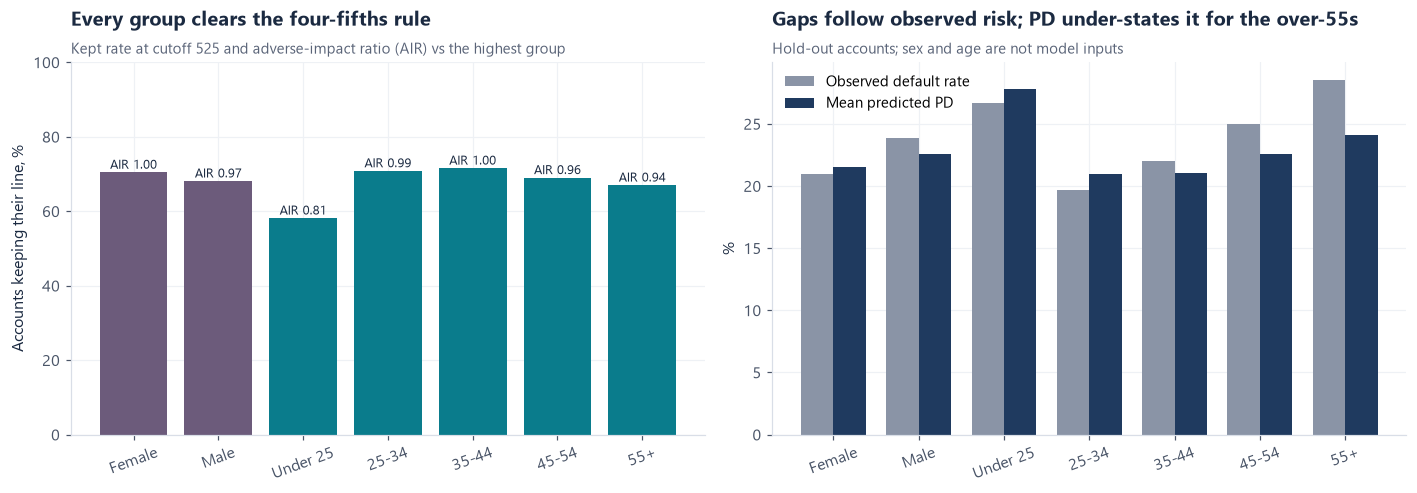

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1]})
labels = [f"{b}" for _, b in fair.index]
xpos = np.arange(len(fair))
cols = [PALETTE["purple"] if g == "Sex" else PALETTE["teal"] for g, _ in fair.index]
a1.bar(xpos, fair["kept_rate"] * 100, color=cols)
for i, (v, air) in enumerate(zip(fair["kept_rate"], fair["AIR"])):
    a1.text(i, v * 100 + 1, f"AIR {air:.2f}", ha="center", fontsize=8.5, color=PALETTE["ink"])
a1.set_xticks(xpos, labels, rotation=20); a1.set_ylabel("Accounts keeping their line, %"); a1.set_ylim(0, 100)
headline(a1, "Every group clears the four-fifths rule", "Kept rate at cutoff 525 and adverse-impact ratio (AIR) vs the highest group")
w = 0.38
a2.bar(xpos - w / 2, fair["default_rate"] * 100, w, color=PALETTE["grey"], label="Observed default rate")
a2.bar(xpos + w / 2, fair["mean_pd"] * 100, w, color=PALETTE["navy"], label="Mean predicted PD")
a2.set_xticks(xpos, labels, rotation=20); a2.set_ylabel("%"); a2.legend(loc="upper left")
headline(a2, "Gaps follow observed risk; PD under-states it for the over-55s", "Hold-out accounts; sex and age are not model inputs")
fig.tight_layout(); _ = savefig(fig, "02-fairness", FIG); plt.show()

* **Sex.** Women keep their line at 70.4%, men at 68.1%: AIR 0.97. AUC is similar (0.78 vs 0.77). PD is slightly low
  for men (calibration ratio 0.94) and slightly high for women (1.03), so the score is not harsher on women.
* **Age.** Under-25s are the closest to the flag: 58% keep their line against 72% of 35-44s, AIR 0.81. Their observed
  default rate is 26.7%, against 22.1% overall, so most of the gap is risk; PD runs 4% high for them (ratio 1.04), so a
  small part is the model. Over-55s get the opposite: PD under-states their risk (observed 28.5%, predicted 24.1%,
  ratio 0.84), so the score is more lenient with them than their risk warrants. Only 333 over-55s are in the hold-out,
  so that ratio is uncertain.
* **Action.** No group breaches the four-fifths rule, but 0.81 is too close to leave alone. Track AIR monthly by age band,
  and before rollout test whether the under-25 gap runs through the credit limit (young customers get lower limits; age
  vs limit rho 0.19 in notebook 01).

## 9. What drives the score: SHAP, permutation importance and reason codes

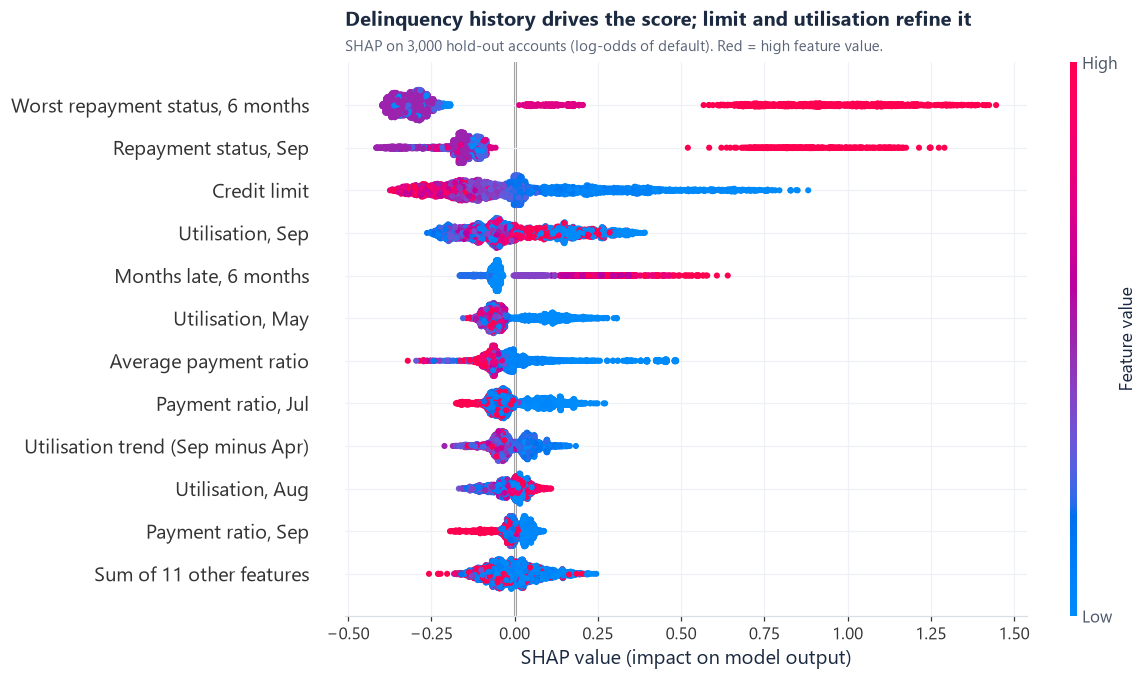

In [21]:
e = explain.shap_explanation(champ, Xte, sample=3000, seed=SEED)
e.feature_names = [F.LABELS[c] for c in Xte.columns]
fig = explain.plot_shap_beeswarm(e, max_display=12, title="Delinquency history drives the score; limit and utilisation refine it",
                                 subtitle="SHAP on 3,000 hold-out accounts (log-odds of default). Red = high feature value.")
_ = savefig(fig, "02-shap-beeswarm", FIG); plt.show()

In [22]:
shap_imp = explain.shap_importance(e)
perm = explain.permutation_table(champ, Xte, yte, n_repeats=3, seed=SEED, labels=F.LABELS)
perm.index = perm["label"]
cmp_imp = shap_imp[["share"]].rename(columns={"share": "SHAP share"}).join(perm[["drop_mean"]].rename(columns={"drop_mean": "AUC drop when shuffled"}))
rho = cmp_imp["SHAP share"].rank().corr(cmp_imp["AUC drop when shuffled"].rank())
print(f"Rank agreement between SHAP and permutation importance: Spearman rho = {rho:.2f}")
cmp_imp.head(10)

Rank agreement between SHAP and permutation importance: Spearman rho = 0.89


,SHAP share,AUC drop when shuffled
feature,,
"Worst repayment status, 6 months",0.2995,0.0536
"Repayment status, Sep",0.1478,0.0216
Credit limit,0.1150,0.0187
"Utilisation, Sep",0.0776,0.0088
"Months late, 6 months",0.0573,0.0028
"Utilisation, May",0.0499,0.0035
Average payment ratio,0.0442,0.0053
"Payment ratio, Jul",0.0424,0.0023
Utilisation trend (Sep minus Apr),0.0311,0.0023


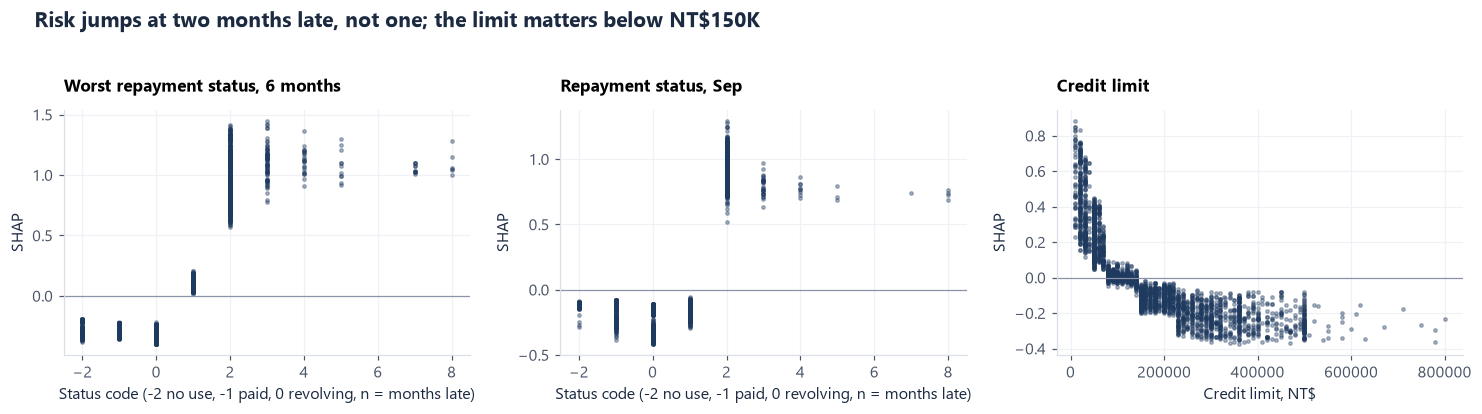

In [23]:
top3 = list(shap_imp.index[:3])
fig = explain.plot_shap_dependence(e, top3, ncols=3, title="Risk jumps at two months late, not one; the limit matters below NT$150K")
for ax, f in zip(fig.axes[:3], top3):
    ax.set_xlabel("Status code (-2 no use, -1 paid, 0 revolving, n = months late)" if "status" in f else "Credit limit, NT$" if "limit" in f else "Feature value")
plt.show()

### Reason codes for a declined account

Any account whose line is cut needs the main reasons, in plain words. Two ways to get them: SHAP on the champion (the
features that pushed this account's PD up the most) and the scorecard method (the characteristics where the account lost
the most points against the best attribute). If the two agree, the explanation is credible.

In [24]:
REASON = {
    "status_1": lambda v: f"Payment status on the latest statement: {F.bucket([v])[0].lower()}",
    "max_status": lambda v: f"Worst payment status in the last six months: {F.bucket([v])[0].lower()}",
    "months_late": lambda v: f"Past due in {int(v)} of the last six months",
    "limit": lambda v: f"Credit limit of NT${v:,.0f} (lower limits carry higher risk)",
    "avg_payratio": lambda v: f"Average payment of {v:.0%} of the previous bill",
    "payratio_1": lambda v: f"Latest payment was {v:.0%} of the previous bill",
    "util_1": lambda v: f"Balance at {v:.0%} of the credit limit",
    "util_trend": lambda v: f"Utilisation changed by {v:+.0%} of the limit since April",
}
low = te.index[(te["score"] < 500).to_numpy()]
pick = te.loc[low, "score"].sort_values().index[len(low) // 2]          # the median declined account: typical, not extreme
row = Xte.loc[[pick]]
e1 = explain.shap_explanation(champ, row)
contrib = pd.Series(e1.values[0], index=Xte.columns).sort_values(ascending=False)
shap_reasons = [REASON.get(f, lambda v, f=f: f"{F.LABELS[f]}: {v:,.2f}")(row[f].iloc[0]) for f in contrib.index[:3]]
lab1 = binner.bin_labels(F.scorecard_frame(row))
used = points["feature"].unique()
lost = pd.Series({f: points.loc[points["feature"] == f, "points"].max() - points.set_index(["feature", "bin"]).loc[(f, lab1[f].iloc[0]), "points"] for f in used}).sort_values(ascending=False)
sc_reasons = [REASON[f](row[f].iloc[0]) for f in lost.index[:3]]
print(f"Account {pick}: champion score {te.loc[pick, 'score']}, PD {te.loc[pick, 'pd']:.1%}, scorecard points {F.scorecard_score(binner, sc_logit, F.scorecard_frame(row))[0]:.0f}")
for i, (a, b) in enumerate(zip(shap_reasons, sc_reasons), 1):
    print(f"Reason {i}  SHAP: {a:<62s} | scorecard: {b}")

Account 4934: champion score 468, PD 65.9%, scorecard points 460
Reason 1  SHAP: Worst payment status in the last six months: 2 months late     | scorecard: Payment status on the latest statement: 2 months late
Reason 2  SHAP: Payment status on the latest statement: 2 months late          | scorecard: Worst payment status in the last six months: 2 months late
Reason 3  SHAP: Credit limit of NT$30,000 (lower limits carry higher risk)     | scorecard: Credit limit of NT$30,000 (lower limits carry higher risk)


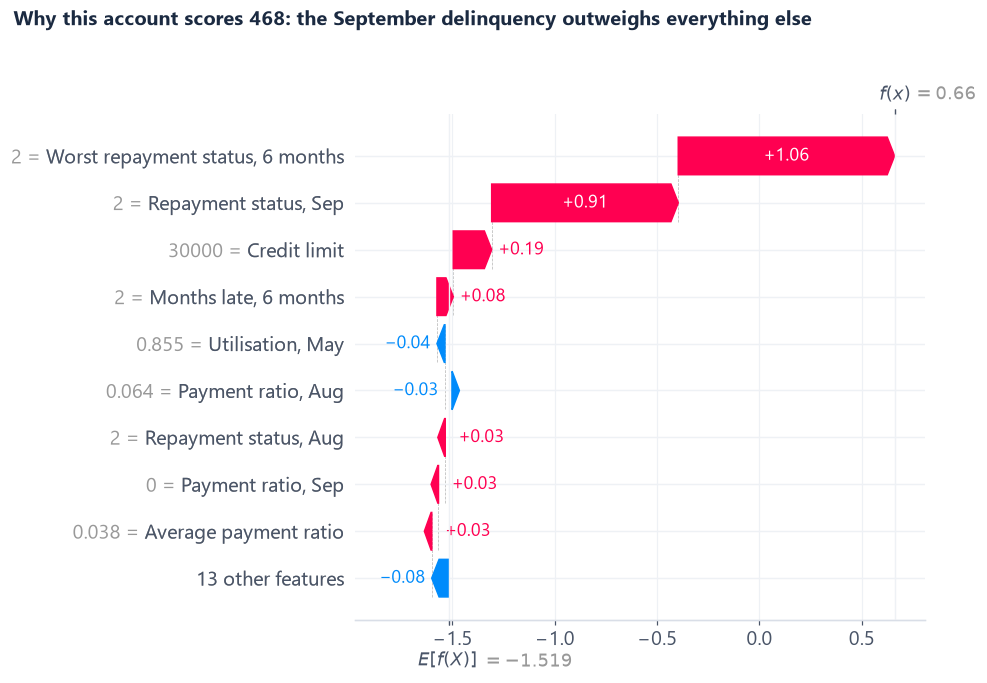

In [25]:
e1.feature_names = [F.LABELS[c] for c in Xte.columns]
fig = explain.plot_shap_waterfall(e1, 0, title=f"Why this account scores {te.loc[pick, 'score']}: the September delinquency outweighs everything else")
plt.show()

* Worst status in six months and September status account for 45% of mean |SHAP|; credit limit is third (12%).
  Permutation importance ranks the features the same way (Spearman rho 0.89), so the picture does not depend on the
  method.
* The dependence plots show thresholds, not slopes. PD jumps when the worst status reaches 2 (two months late) and
  barely moves after that. A one-month delay adds little once the six-month history is known. The limit pushes risk up
  only below about NT$150K.
* For the median declined account (score 468, PD 66%, 460 scorecard points), SHAP and the scorecard give the same
  three reasons in a slightly different order: two months late on the latest statement, two months late as the worst
  status in six months, and a NT$30,000 credit limit. Two independent methods agreeing is what makes a reason code
  defensible when a customer complains.

## 10. Stability

A behavioural score is recomputed every month, so its inputs have to be stable month to month. With one snapshot the
score itself cannot be re-run on a later month, but the inputs can: the same measure (status bucket, utilisation,
payment ratio) is available for every month, so month-on-month PSI is exactly what a monthly monitoring report would see.

In [26]:
rows = []
for k in range(1, 5):
    new, old = f"{F.MONTHS[k - 1]:%b}", f"{F.MONTHS[k]:%b}"
    a = pd.DataFrame({"status": F.bucket(u[f"PAY_{k + 1}"]), "util": X[f"util_{k + 1}"], "payratio": X[f"payratio_{k + 1}"]})
    b = pd.DataFrame({"status": F.bucket(u[f"PAY_{k}"]), "util": X[f"util_{k}"], "payratio": X[f"payratio_{k}"]})
    s = eda.stability(a, b, ["status", "util", "payratio"])["psi"]
    rows.append({"months": f"{old} -> {new}", **{f"PSI {c}": s[c] for c in ("status", "util", "payratio")}})
psi_month = pd.DataFrame(rows).set_index("months")
sc_tr = F.score_points(champ.predict_proba(Xtr)[:, 1])
print(f"Score PSI, training vs hold-out accounts: {eda.psi(sc_tr, te['score']):.4f} (same period, random split: expected near zero)")
psi_month

Score PSI, training vs hold-out accounts: 0.0017 (same period, random split: expected near zero)


,PSI status,PSI util,PSI payratio
months,,,
Aug -> Sep,0.6253,0.0037,0.0018
Jul -> Aug,0.0032,0.0042,0.0706
Jun -> Jul,0.0063,0.0170,0.0265
May -> Jun,0.0045,0.0107,0.0072


Month-on-month PSI for utilisation and payment ratio stays below 0.1 (0.07 at most). Status jumps to 0.63 from August
to September. That is not a change in behaviour: it is the "one month late" code appearing for the first time in
September (notebook 01). Monitoring needs the same lesson: a PSI alert needs a triage step, because a coding change looks
exactly like a population shift. Score PSI between training and hold-out accounts is 0.002, as expected for a random
split within one month.

## 11. Decision

* **Keep the published champion** (HistGradientBoosting: AUC 0.776, Gini 0.552, KS 0.421). It is calibrated and the
  report's cutoff numbers reproduce exactly.
* **Make the monotone LightGBM the candidate for the next release.** At least as accurate (+0.002 AUC, CI 0.000 to
  +0.004), the same defaults caught at the 525 volume (63.1% vs 63.0%), and a guarantee that a worse status or a lower
  payment ratio can never lower a PD. That guarantee costs 0.0016 AUC against the unconstrained version.
* **Use the WoE scorecard where a points table is mandatory.** Six characteristics and every point explainable, but 0.030
  AUC lower. At the 525 volume that means 2.4 points fewer defaults caught, about 47 per 9,000 accounts.
* **Policy bands:** decrease the line and call below 500 (14% of accounts, 62% bad rate); analyst review at 500-524 (16%,
  31%); maintain at 525-574 (67%, 12%); limit increase eligible at 575+ (2.7%, 2.9%).

## 12. Limitations

* **2005 Taiwan.** The book was observed during the 2005-06 Taiwanese card-debt crisis; default rates of 22% are far above
  a normal portfolio. Levels (PD, bad rates, the 525 cutoff economics) do not transfer; the ranking method does.
* **Behavioural, not application, score.** It ranks existing accounts using six months of statements. It cannot score a
  new applicant, and the credit limit input partly reflects the issuer's earlier risk judgement.
* **One performance month.** The target is a single October payment. A production PD needs a 12-month default
  definition, several cohorts and an out-of-time hold-out; none exist in this file, so stability over time is unproven.
* **Exposure and LGD are simplifications.** Exposure at default is the September balance or half the line; LGD is one
  assumed number. Expected-loss shares are robust to LGD; money amounts are not.
* **Fairness check is outcome-based.** Group comparisons use sex and age as recorded. Proxy effects through credit limit
  are small here (notebook 01) but must be re-tested on any new population.

## 13. What I would do next

* Rebuild the target as default within 12 months on a multi-cohort extract and validate out of time.
* Replace the half-line exposure rule with a credit-conversion-factor model for undrawn limits.
* Run the line-decrease policy as a champion/challenger test (random 10% of the sub-525 group keeps its line) to measure
  the causal effect on losses and attrition before rolling out.

In [27]:
report.update_metrics(METRICS, "02_pd_scorecard", {
    "parity": {k: {"published": float(r["published"]), "reproduced": float(r["reproduced"])} for k, r in parity.iterrows()},
    "cv_auc": cvt["roc_auc_mean"].to_dict(), "cv_auc_sd": cvt["roc_auc_std"].to_dict(),
    "test": {k: {"auc": float(r["AUC"]), "auc_ci": r["AUC 95% CI"], "gini": float(r["Gini"]), "ks": float(r["KS"]), "brier": float(r["Brier"])} for k, r in mt.iterrows()},
    "paired_tests": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in paired.iterrows()},
    "scorecard_characteristics": [str(f) for f in points["feature"].unique()],
    "cutoff_525": cut,
    "same_volume_defaults_caught": {k: float(v["defaults caught"]) for k, v in same_vol.items()},
    "fairness_min_air": float(fair["AIR"].min()),
    "fairness": {f"{g}: {b}": {"kept_rate": float(r["kept_rate"]), "air": float(r["AIR"]), "auc": float(r["auc"])} for (g, b), r in fair.iterrows()},
    "lgbm_best_params": {k: v for k, v in best.items() if k != "monotone_constraints"},
})
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 228 s
